In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [4]:
file_path = "CH2O_09337_DFRS_DS95_2021_272_00_57/calibrated/ch2o_frs_calibrated_01_21272001904.csv"

df = pd.read_csv(file_path, header=None)

df.columns = [
    "Day",
    "Time",
    "Frequency",
    "Value_1",
    "Value_2",
    "Signal"
]

df.head()

,Day,Time,Frequency,Value_1,Value_2,Signal
0,2021-272,1144.00000,2.240000e+09,2.239989e+09,2.239989e+09,17.477752
1,2021-272,1144.08192,2.240000e+09,2.239989e+09,2.239989e+09,17.492057
2,2021-272,1144.16384,2.240000e+09,2.239989e+09,2.239989e+09,17.385770
3,2021-272,1144.24576,2.240000e+09,2.239989e+09,2.239989e+09,17.296193
4,2021-272,1144.32768,2.240000e+09,2.239989e+09,2.239989e+09,17.574878


In [5]:
import os

print(os.getcwd())

/Users/sachin/Untitled Folder 2


In [9]:
signal_min = df["Signal"].min()
signal_max = df["Signal"].max()

df["Ice_Probability"] = (
    (df["Signal"] - signal_min)
    / (signal_max - signal_min)
) * 100

df.head()

,Day,Time,Frequency,Value_1,Value_2,Signal,Suitability_Score,Ice_Probability
0,2021-272,1144.00000,2.240000e+09,2.239989e+09,2.239989e+09,17.477752,0.256001,25.600146
1,2021-272,1144.08192,2.240000e+09,2.239989e+09,2.239989e+09,17.492057,0.256002,25.600151
2,2021-272,1144.16384,2.240000e+09,2.239989e+09,2.239989e+09,17.385770,0.256001,25.600114
3,2021-272,1144.24576,2.240000e+09,2.239989e+09,2.239989e+09,17.296193,0.256001,25.600083
4,2021-272,1144.32768,2.240000e+09,2.239989e+09,2.239989e+09,17.574878,0.256002,25.600180


In [10]:
threshold = df["Signal"].quantile(0.95)

candidate_df = df[
    df["Signal"] >= threshold
].copy()

print("Candidates:", len(candidate_df))

Candidates: 623


In [11]:
candidate_df["Rank_Score"] = (
    candidate_df["Signal"]
    / candidate_df["Signal"].max()
) * 100

candidate_df.head()

,Day,Time,Frequency,Value_1,Value_2,Signal,Suitability_Score,Ice_Probability,Rank_Score
122,2021-272,1153.99424,2.240000e+09,2.240200e+09,2.239989e+09,210683.615156,0.996146,99.614643,99.482089
123,2021-272,1154.07616,2.240000e+09,2.240200e+09,2.239989e+09,210684.007046,0.996148,99.614781,99.482274
124,2021-272,1154.15808,2.240000e+09,2.240200e+09,2.239989e+09,210684.384929,0.996149,99.614914,99.482453
125,2021-272,1154.24000,2.240000e+09,2.240200e+09,2.239989e+09,210684.754993,0.996150,99.615044,99.482628
126,2021-272,1154.32192,2.240000e+09,2.240200e+09,2.239989e+09,210685.093604,0.996152,99.615163,99.482787


In [12]:
candidate_df["Landing_Suitability"] = (
    0.7 * candidate_df["Rank_Score"] +
    0.3 * candidate_df["Ice_Probability"]
)

candidate_df.head()

,Day,Time,Frequency,Value_1,Value_2,Signal,Suitability_Score,Ice_Probability,Rank_Score,Landing_Suitability
122,2021-272,1153.99424,2.240000e+09,2.240200e+09,2.239989e+09,210683.615156,0.996146,99.614643,99.482089,99.521856
123,2021-272,1154.07616,2.240000e+09,2.240200e+09,2.239989e+09,210684.007046,0.996148,99.614781,99.482274,99.522026
124,2021-272,1154.15808,2.240000e+09,2.240200e+09,2.239989e+09,210684.384929,0.996149,99.614914,99.482453,99.522191
125,2021-272,1154.24000,2.240000e+09,2.240200e+09,2.239989e+09,210684.754993,0.996150,99.615044,99.482628,99.522352
126,2021-272,1154.32192,2.240000e+09,2.240200e+09,2.239989e+09,210685.093604,0.996152,99.615163,99.482787,99.522500


In [13]:
best_sites = candidate_df.sort_values(
    "Landing_Suitability",
    ascending=False
)

best_sites.head(20)

,Day,Time,Frequency,Value_1,Value_2,Signal,Suitability_Score,Ice_Probability,Rank_Score,Landing_Suitability
6030,2021-272,1637.977588,2.240000e+09,2.240200e+09,2.239988e+09,211780.448691,1.000000,100.000000,100.000000,100.000000
6031,2021-272,1638.059508,2.240000e+09,2.240200e+09,2.239988e+09,211780.443540,1.000000,99.999998,99.999998,99.999998
6032,2021-272,1638.141428,2.240000e+09,2.240200e+09,2.239988e+09,211780.438323,1.000000,99.999996,99.999995,99.999995
6033,2021-272,1638.223348,2.240000e+09,2.240200e+09,2.239988e+09,211780.433040,1.000000,99.999995,99.999993,99.999993
6034,2021-272,1638.305268,2.240000e+09,2.240200e+09,2.239988e+09,211780.427693,1.000000,99.999993,99.999990,99.999991
6035,2021-272,1638.387188,2.240000e+09,2.240200e+09,2.239988e+09,211780.422280,1.000000,99.999991,99.999988,99.999988
6036,2021-272,1638.469108,2.240000e+09,2.240200e+09,2.239988e+09,211780.416803,1.000000,99.999989,99.999985,99.999986
6037,2021-272,1638.551028,2.240000e+09,2.240200e+09,2.239988e+09,211780.411261,1.000000,99.999987,99.999982,99.999984
6038,2021-272,1638.632948,2.240000e+09,2.240200e+09,2.239988e+09,211780.405653,1.000000,99.999985,99.999980,99.999981
6039,2021-272,1638.714868,2.240000e+09,2.240200e+09,2.239988e+09,211780.399981,1.000000,99.999983,99.999977,99.999979


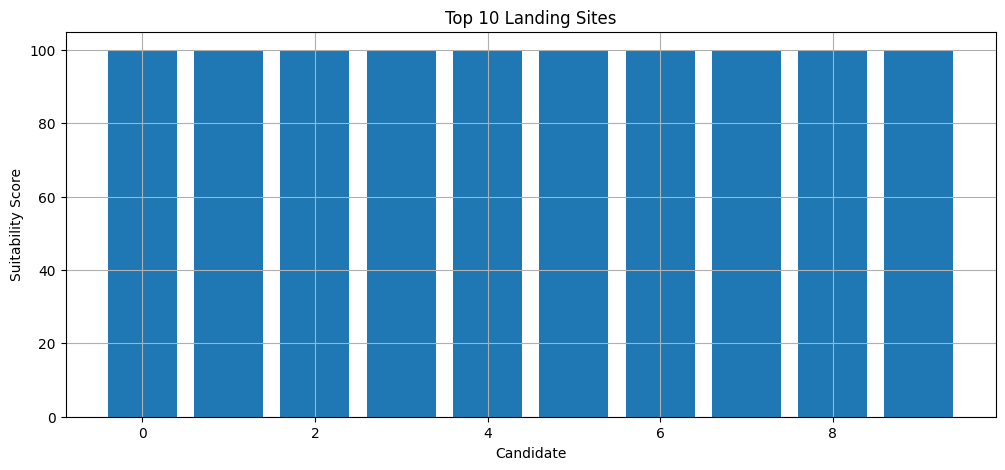

In [14]:
top10 = best_sites.head(10)

plt.figure(figsize=(12,5))

plt.bar(
    range(len(top10)),
    top10["Landing_Suitability"]
)

plt.title("Top 10 Landing Sites")
plt.xlabel("Candidate")
plt.ylabel("Suitability Score")

plt.grid(True)

plt.show()

In [15]:
import os

os.makedirs("../results", exist_ok=True)

best_sites.to_csv(
    "../results/top_landing_sites.csv",
    index=False
)

print("Results Saved")

Results Saved


# Landing Site Suitability Ranking Model



This notebook ranks potential lunar landing sites using Chandrayaan-2 DFSAR radar reflections and ice probability estimation.